# Part 2 Showcase: Randomness you can see 🎲

**Course part 2 - Decisions and Loops** (uses Lectures 4, 5 and 6: `if`/`elif`/`else`, `and`/`or`/`not`, lists, `while`, `for`, `range`, and the loop recipes: total, average, count, max).

What you will build today:
1. **Dice**: roll a die 6,000 times and two dice 10,000 times. Why is **7** the king of board games?
2. **Recipes for randomness**: pictures made of random dots - a square, a cloud, a ring and a smiley.
3. **Monte Carlo**: find the number **pi = 3.14159...** by throwing random darts.

> 🐍 *Pip says: "Nothing here is hard. It's loops, lists and `if` - you know all of it. The computer just does it 10,000 times without getting bored."*

**How to use this notebook:** run the cells from top to bottom (Shift+Enter). Two new things appear, and you don't need to understand them yet:
- `import` opens a ready-made toolbox (Lecture 9 explains it).
- The **plotting** cells use matplotlib - *plotting is Lecture 10, for now just run them*.

## 0. Open the toolboxes

`random` is Python's box of dice. `random.seed(7)` makes the "random" numbers the **same every time you run** - so your numbers match the slides. Change 7 to any number to get a different (but still random-looking) run.

In [1]:
import random                    # Python's box of dice (import = open a toolbox, Lecture 9)
import math                      # math tools - we only need math.pi
import matplotlib.pyplot as plt  # drawing tools (plotting is Lecture 10 - just run it)

plt.rcParams["font.size"] = 12   # bigger text on the plots
random.seed(7)                   # same "random" numbers every run -> matches the slides
print("Ready to roll!")

Ready to roll!


### Meet `random`
- `random.randint(1, 6)` - a whole number from 1 to 6 (both included). A die!
- `random.random()` - a decimal number between 0 and 1.
- `random.uniform(-1, 1)` - a decimal number between -1 and 1.
- `random.choice(a_list)` - picks one item from a list.

In [2]:
random.seed(7)
for i in range(5):
    roll = random.randint(1, 6)    # a die: 1, 2, 3, 4, 5 or 6
    print(f"Roll {i + 1}: {roll}")

Roll 1: 3
Roll 2: 2
Roll 3: 4
Roll 4: 6
Roll 5: 1


In [3]:
print(random.random())                                # between 0 and 1
print(random.uniform(-1, 1))                          # between -1 and 1
print(random.choice(["pizza", "falafel", "sushi"]))   # can't decide on dinner? let Python pick

0.07243628666754276
0.0717640086133784
falafel


# 1. Dice 🎲

## 1a. One die, 6,000 rolls
A fair die should give every face about **1/6** of the time: 6,000 / 6 = **1,000** each.
Let's check with a **counting list** (a tally sheet): `counts[0]` counts the 1s, `counts[1]` the 2s, ..., `counts[5]` the 6s.
(Face 1 goes to slot 0 because lists start counting at 0 - Lecture 5.)

In [4]:
random.seed(7)
counts = [0, 0, 0, 0, 0, 0]       # counts[0] is for face 1, ..., counts[5] is for face 6
for i in range(6000):
    face = random.randint(1, 6)
    slot = face - 1               # face 1 -> slot 0, ..., face 6 -> slot 5
    counts[slot] = counts[slot] + 1   # one more roll for this face
print(counts)
print("Total rolls:", sum(counts))

[1038, 1020, 1000, 969, 953, 1020]
Total rolls: 6000


Every face is **close to 1,000, but not exactly 1,000**. That's what randomness looks like!
Let's draw it (plotting is Lecture 10 - just run it).

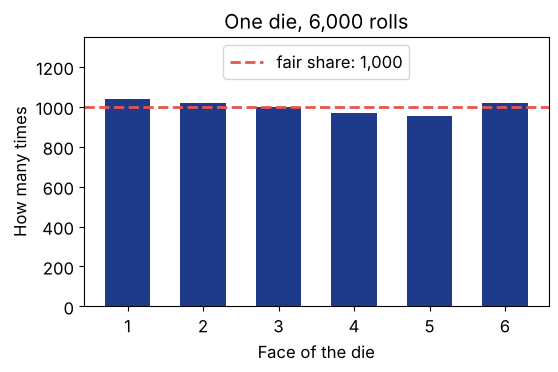

In [5]:
faces = [1, 2, 3, 4, 5, 6]
plt.figure(figsize=(6, 3.5))
plt.bar(faces, counts, color="#1E3A8A", width=0.6)
plt.axhline(1000, color="#E8554E", linestyle="--", linewidth=2, label="fair share: 1,000")
plt.xlabel("Face of the die")
plt.ylabel("How many times")
plt.title("One die, 6,000 rolls")
plt.legend(loc="upper center")
plt.ylim(0, 1350)
plt.show()

> **Try this:** change `6000` to `60` and run both cells again. With only 60 rolls the bars are much bumpier. More rolls = closer to fair.

## 1b. Two dice, 10,000 rolls
Now roll **two** dice and add them, like in *Catan* or *Monopoly*. The sum can be 2 (1+1) up to 12 (6+6).

We need a slot for each sum, so we make a tally list of 13 zeros (slots 0 to 12) and simply never use slots 0 and 1.
`[0] * 13` repeats `[0]` 13 times - just like `"ha" * 3` gives `"hahaha"` (Lecture 2).

In [6]:
random.seed(7)
tally = [0] * 13                  # a tally sheet with 13 slots: 0..12 (we only use 2..12)
for i in range(10000):
    die1 = random.randint(1, 6)
    die2 = random.randint(1, 6)
    total = die1 + die2
    tally[total] = tally[total] + 1
for total in range(2, 13):
    print(f"Sum {total:2}: {tally[total]}")

Sum  2: 278
Sum  3: 565
Sum  4: 855
Sum  5: 1119
Sum  6: 1382
Sum  7: 1700
Sum  8: 1391
Sum  9: 1061
Sum 10: 826
Sum 11: 517
Sum 12: 306


Which sum wins? Use the **maximum recipe** from Lecture 6: remember the best so far, and replace it when you find a better one.

In [7]:
best_sum = 2                      # "best so far" starts with the first sum
for total in range(2, 13):
    if tally[total] > tally[best_sum]:
        best_sum = total          # found a more common sum
print("Most common sum:", best_sum)

Most common sum: 7


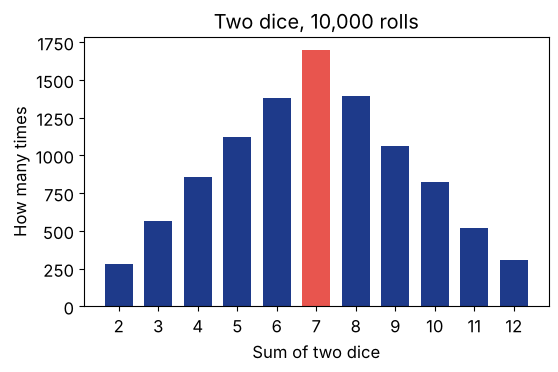

In [8]:
sums = []
heights = []
colors = []
for total in range(2, 13):
    sums.append(total)
    heights.append(tally[total])
    if total == 7:
        colors.append("#E8554E")  # the star of the show
    else:
        colors.append("#1E3A8A")
plt.figure(figsize=(6, 3.5))
plt.bar(sums, heights, color=colors, width=0.7)
plt.xticks(sums)
plt.xlabel("Sum of two dice")
plt.ylabel("How many times")
plt.title("Two dice, 10,000 rolls")
plt.show()

**A triangle, not flat!** 7 is the most common sum, 2 and 12 are the rarest.

🎲 **Board games know this:**
- In *Catan*, rolling a 7 moves the robber - it happens more than any other number. The 6 and 8 fields (right next to 7) are the most valuable land.
- In *Monopoly*, you move by the sum of two dice, so the squares about 7 steps from where many players stand get landed on more often.

## 1c. Why 7? Count every possibility
Two dice can land in 6 x 6 = **36** ways (first die 1..6, second die 1..6). How many of those give 7?
1+6, 2+5, 3+4, 4+3, 5+2, 6+1 = **6 ways**. But only **one** way gives 2 (1+1).

Let the computer count all 36 ways with **a loop inside a loop**: for every face of the first die, try every face of the second die.

In [9]:
ways = [0] * 13
for die1 in range(1, 7):          # every face of the first die...
    for die2 in range(1, 7):      # ...with every face of the second die
        ways[die1 + die2] = ways[die1 + die2] + 1
print("Ways:", ways[2:])        # sums 2 to 12
print(f"Sum 7: {ways[7]} ways out of 36 = {100 * ways[7] / 36:.1f}%")
print(f"Our 10,000 rolls:   {100 * tally[7] / 10000:.1f}%")

Ways: [1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]
Sum 7: 6 ways out of 36 = 16.7%
Our 10,000 rolls:   17.0%


The **exact** answer (6/36 = 16.7%) and our **simulation** agree closely. Let's see all sums together: bars = our rolls, dots = exact math.

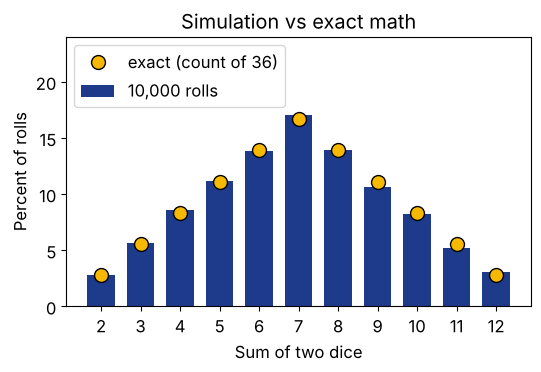

In [10]:
rolled_percent = []
exact_percent = []
for total in range(2, 13):
    rolled_percent.append(100 * tally[total] / 10000)
    exact_percent.append(100 * ways[total] / 36)
plt.figure(figsize=(6, 3.5))
plt.bar(sums, rolled_percent, color="#1E3A8A", width=0.7, label="10,000 rolls")
plt.plot(sums, exact_percent, "o", color="#F6B800", markersize=10,
         markeredgecolor="black", label="exact (count of 36)")
plt.xticks(sums)
plt.ylim(0, 24)
plt.xlabel("Sum of two dice")
plt.ylabel("Percent of rolls")
plt.title("Simulation vs exact math")
plt.legend(loc="upper left")
plt.show()

> **Try this:**
> - Roll **three** dice instead of two (sums 3 to 18). Which sum wins now? (Hint: there is a tie!)
> - Make an unfair die: `face = random.choice([1, 2, 3, 4, 5, 6, 6])`. What happens to the bar of 6?

# 2. Recipes for randomness 🍰

A **distribution** is a *recipe for randomness*: it tells the computer which numbers should come out often and which rarely.

| Recipe | In plain words | In real life | Python |
|---|---|---|---|
| **Uniform** | every value equally likely | a die, a random seat in class | `random.uniform(a, b)`, `random.randint(1, 6)` |
| **Normal ("bell")** | most values near the middle, few far away | people's heights, exam grades | `random.gauss(middle, spread)` |
| **Exponential** | short waits are common, long waits are rare | waiting for a bus that comes at random times | `random.expovariate(1 / average)` |

Below, each dot is a point **(x, y)**: x says how far right, y how far up - like a seat in a cinema (row and seat number).

## 2a. Uniform square and bell cloud

In [11]:
random.seed(7)
square_x = []
square_y = []
bell_x = []
bell_y = []
for i in range(1500):
    square_x.append(random.uniform(-1, 1))   # anywhere in the square, all equally likely
    square_y.append(random.uniform(-1, 1))
    bell_x.append(random.gauss(0, 0.35))     # middle 0, spread 0.35: most dots near the center
    bell_y.append(random.gauss(0, 0.35))
print(len(square_x), "square dots and", len(bell_x), "bell dots")

1500 square dots and 1500 bell dots


## 2b. A ring: keep a dot only `if` it's in the ring
Recipe: throw a dot anywhere in the square. **If** its distance from the center is between 0.6 and 1, keep it. Otherwise throw it away.

The distance from the center is $\sqrt{x^2 + y^2}$ (Pythagoras). Trick: instead of the square root, compare the *squares*: `x * x + y * y` with `0.6 ** 2` and `1`.
We use a **`while` loop** because we don't know in advance how many tries we need to collect 1,500 dots.

In [12]:
random.seed(7)
ring_x = []
ring_y = []
tries = 0
while len(ring_x) < 1500:                 # until we have 1500 dots
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)
    tries = tries + 1
    distance2 = x * x + y * y              # (distance from the center) squared
    if distance2 >= 0.6 ** 2 and distance2 <= 1:
        ring_x.append(x)                   # inside the ring: keep it
        ring_y.append(y)
print(f"Tried {tries} dots, kept {len(ring_x)}")

Tried 2910 dots, kept 1500


## 2c. A smiley made of random dots 🙂
Same trick with more rules (`and`, `or`, `not` from Lecture 4). A dot is kept **if** it is in the face **and not** in an eye **and not** in the mouth.
- Face: circle of radius 1. Eyes: small circles (radius 0.15) at (-0.35, 0.35) and (0.35, 0.35).
- Mouth: a piece of ring (distance 0.45 to 0.6), only the bottom part (`y < -0.1`).

In [13]:
random.seed(7)
smile_x = []
smile_y = []
for i in range(6000):
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)
    in_face = x * x + y * y <= 1
    in_left_eye = (x + 0.35) ** 2 + (y - 0.35) ** 2 <= 0.15 ** 2
    in_right_eye = (x - 0.35) ** 2 + (y - 0.35) ** 2 <= 0.15 ** 2
    in_mouth = 0.45 ** 2 <= x * x + y * y <= 0.6 ** 2 and y < -0.1
    if in_face and not (in_left_eye or in_right_eye or in_mouth):
        smile_x.append(x)
        smile_y.append(y)
print(f"Kept {len(smile_x)} of 6000 dots")

Kept 4189 of 6000 dots


### The gallery (plotting is Lecture 10 - just run it)

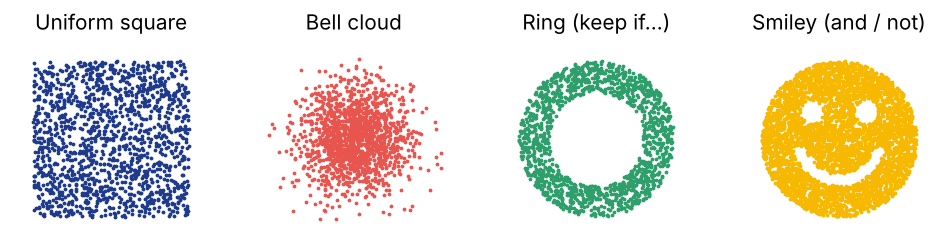

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
pictures = [[square_x, square_y, "Uniform square", "#1E3A8A"],
            [bell_x, bell_y, "Bell cloud", "#E8554E"],
            [ring_x, ring_y, "Ring (keep if...)", "#2E9E6B"],
            [smile_x, smile_y, "Smiley (and / not)", "#F6B800"]]
for k in range(4):
    xs, ys, title, color = pictures[k]
    axes[k].scatter(xs, ys, s=3, color=color)
    axes[k].set_title(title, fontsize=15)
    axes[k].set_xlim(-1.3, 1.3)
    axes[k].set_ylim(-1.3, 1.3)
    axes[k].set_aspect("equal")
    axes[k].axis("off")
plt.show()

> **Try this:**
> - In the bell cloud, change the spread `0.35` to `0.1`. What happens?
> - Make the ring thinner: keep dots between 0.9 and 1.
> - Give the smiley a nose!

## 2d. Histograms: how often does each x come out?
A **histogram** chops the number line into small bins and counts how many values fall in each bin (a counting list, like our dice!).

And a third recipe: **waiting for the bus**. If a bus shows up at random moments, about every 10 minutes on average, most waits are short, and very long waits are rare.

In [15]:
random.seed(7)
bus_waits = []
for i in range(1500):
    bus_waits.append(random.expovariate(1 / 10))   # average wait: 10 minutes
long_waits = 0
for wait in bus_waits:
    if wait > 20:
        long_waits = long_waits + 1
print(f"Average wait: {sum(bus_waits) / len(bus_waits):.1f} min")
print(f"Longest wait: {max(bus_waits):.1f} min")
print(f"Waited more than 20 min: {long_waits} of {len(bus_waits)} times")

Average wait: 9.7 min
Longest wait: 67.2 min
Waited more than 20 min: 201 of 1500 times


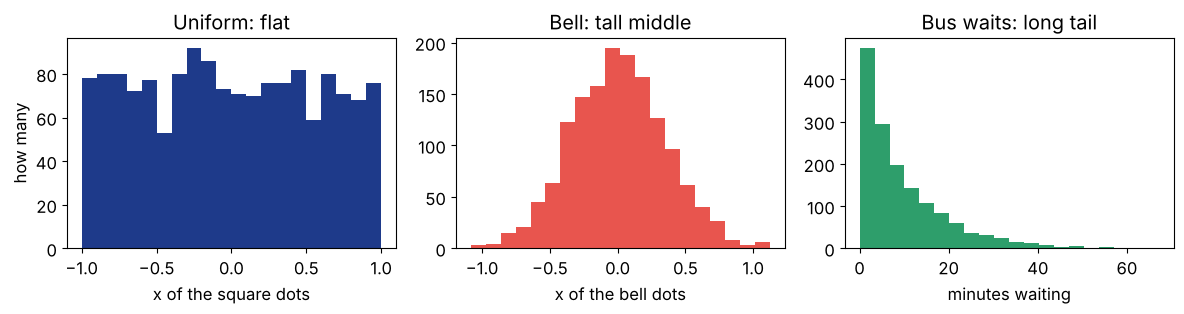

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(square_x, bins=20, color="#1E3A8A")
axes[0].set_title("Uniform: flat")
axes[1].hist(bell_x, bins=20, color="#E8554E")
axes[1].set_title("Bell: tall middle")
axes[2].hist(bus_waits, bins=20, color="#2E9E6B")
axes[2].set_title("Bus waits: long tail")
axes[0].set_xlabel("x of the square dots")
axes[1].set_xlabel("x of the bell dots")
axes[2].set_xlabel("minutes waiting")
axes[0].set_ylabel("how many")
plt.tight_layout()
plt.show()

Same idea as the dice bars:
- **Uniform**: all bins about equal (like the single die).
- **Bell**: a hill in the middle - like the heights of people in a big lecture hall.
- **Bus**: a big pile of short waits and a long thin "tail" of unlucky days.

# 3. Monte Carlo: find pi with darts 🎯

**The idea.** Draw a square from -1 to 1 (side 2, area 4) and a circle of radius 1 inside it (area pi x 1 x 1 = pi).
Throw darts **completely at random** into the square. The share of darts that land inside the circle is about

$$\frac{\text{circle area}}{\text{square area}} = \frac{\pi}{4} \quad\Longrightarrow\quad \pi \approx 4 \times \frac{\text{darts inside}}{\text{all darts}}$$

A dart at (x, y) is inside the circle **if** `x * x + y * y <= 1` (the same distance test as the ring).
This trick - *answer a question by running lots of random experiments* - is called the **Monte Carlo method**, named after the famous casino in Monaco.

In [17]:
random.seed(7)
darts = 2000
inside = 0
dart_x = []
dart_y = []
for i in range(darts):
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)
    dart_x.append(x)
    dart_y.append(y)
    if x * x + y * y <= 1:        # inside the circle (radius 1)?
        inside = inside + 1
pi_estimate = 4 * inside / darts
print(f"{inside} of {darts} darts inside -> pi is about {pi_estimate}")

1560 of 2000 darts inside -> pi is about 3.12


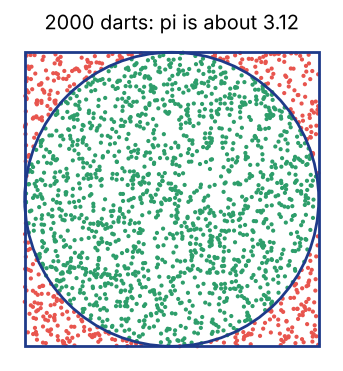

In [18]:
dart_colors = []
for k in range(darts):
    if dart_x[k] ** 2 + dart_y[k] ** 2 <= 1:
        dart_colors.append("#2E9E6B")   # green: inside
    else:
        dart_colors.append("#E8554E")   # coral: outside
plt.figure(figsize=(4.2, 4.2))
plt.scatter(dart_x, dart_y, s=4, color=dart_colors)
board = plt.gca()                       # draw the dartboard: a circle inside a square
board.add_patch(plt.Circle((0, 0), 1, fill=False, color="#1E3A8A", linewidth=2))
board.add_patch(plt.Rectangle((-1, -1), 2, 2, fill=False, color="#1E3A8A", linewidth=2))
plt.title(f"{darts} darts: pi is about {pi_estimate}")
board.set_aspect("equal")
plt.axis("off")
plt.show()

### More darts, better guess
Now throw **100,000** darts and write down the estimate after every dart. We print a short report after 10, 100, 1,000, 10,000 and 100,000 darts.

In [19]:
random.seed(7)
inside = 0
history_darts = []
history_pi = []
for i in range(1, 100001):                 # dart number 1, 2, ..., 100000
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)
    if x * x + y * y <= 1:
        inside = inside + 1
    history_darts.append(i)
    history_pi.append(4 * inside / i)      # the estimate so far
    if i in [10, 100, 1000, 10000, 100000]:
        print(f"{i:>7} darts: pi is about {4 * inside / i:.4f}")
print(f"   Real pi:          {math.pi:.4f}")

     10 darts: pi is about 3.6000
    100 darts: pi is about 3.2000
   1000 darts: pi is about 3.0320
  10000 darts: pi is about 3.1404


 100000 darts: pi is about 3.1400
   Real pi:          3.1416


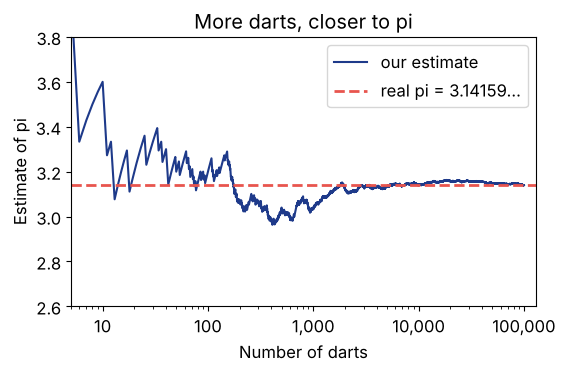

In [20]:
plt.figure(figsize=(6, 3.5))
plt.plot(history_darts, history_pi, color="#1E3A8A", linewidth=1.5, label="our estimate")
plt.axhline(math.pi, color="#E8554E", linestyle="--", linewidth=2, label="real pi = 3.14159...")
plt.xscale("log")                          # each step to the right = 10 times more darts
plt.xticks([10, 100, 1000, 10000, 100000], ["10", "100", "1,000", "10,000", "100,000"])
plt.xlim(5, 130000)
plt.ylim(2.6, 3.8)
plt.xlabel("Number of darts")
plt.ylabel("Estimate of pi")
plt.title("More darts, closer to pi")
plt.legend(loc="upper right")
plt.show()

Notice the x-axis: each tick is **10 times** more darts than the one before. The first few darts jump around wildly, then the estimate settles down near 3.14.

### Watch the darts fly (animation)
*This cell uses a small function (Lecture 7) and animation tools - just run it and press play.*

In [21]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(3.2, 3.2), dpi=72)   # small, so the notebook stays light
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_aspect("equal")
ax.axis("off")
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="#1E3A8A", linewidth=1.5))
ax.add_patch(plt.Rectangle((-1, -1), 2, 2, fill=False, color="#1E3A8A", linewidth=1.5))
dots = ax.scatter([], [], s=4)
per_frame = 80                                # 80 new darts in every frame

def update(frame):
    n = (frame + 1) * per_frame               # darts thrown so far
    dots.set_offsets(list(zip(dart_x[:n], dart_y[:n])))
    dots.set_color(dart_colors[:n])
    n_inside = dart_colors[:n].count("#2E9E6B")
    ax.set_title(f"{n} darts: pi = {4 * n_inside / n:.3f}", fontsize=11)

anim = FuncAnimation(fig, update, frames=darts // per_frame, interval=200)
plt.close()                                   # don't print an extra still picture
HTML(anim.to_jshtml())

### Optional bonus: NumPy (Lecture 9)
*Optional - skip it if you like.* NumPy can throw **a million** darts without writing a loop. You'll learn how in Lecture 9.

In [22]:
# OPTIONAL - NumPy is Lecture 9. A million darts, no loop!
import numpy as np
rng = np.random.default_rng(7)
x_million = rng.uniform(-1, 1, 1_000_000)
y_million = rng.uniform(-1, 1, 1_000_000)
inside_million = (x_million ** 2 + y_million ** 2 <= 1).sum()
print(f"A million darts: pi is about {4 * inside_million / 1_000_000:.4f}")

A million darts: pi is about 3.1430


## Where is Monte Carlo used in real life?
When a question is too messy for a clean formula, run it **thousands of times with random inputs** and look at the results:
- 🌦️ **Weather forecasts**: run the forecast many times, each starting from slightly different measurements. "70% chance of rain" = it rained in about 70% of the runs.
- 🎮 **Games**: a game AI can play many random games from the current position and choose the move that wins most often.
- 💰 **Finance**: try thousands of possible futures for prices to see how risky an investment is.
- 🛡️ **Insurance**: simulate many years of accidents, floods or fires to set a fair price.

# Challenges 🏆

**Easy** - Roll **three** dice 10,000 times and count each sum (3..18). Which sum is the most common? (There's a tie!)

**Medium** - "At least one 6 in 4 rolls": repeat the experiment 10,000 times (a loop with an inner loop of 4 rolls) and count how often you get at least one 6. Is it more or less than 50%? Gamblers in 17th-century France bet on exactly this.

**Spicy** - Draw your own picture with random dots: a heart, a star, the letter of your name, or a pizza with toppings. Then use Monte Carlo to estimate **what fraction of the square** your picture covers.

> 🐍 *Pip says: "You just used loops, lists and `if` to do real science. Not bad for Part 2!"*